### autograd(자동미분)
: pytorch에서 연산 과정을 추적하고 역전파를 통해 미분값을 자동으로 계산하는 기능
- **미분 계산 자동화**
- **기울기 계산**: 각 입력값과 모델의 가중치가 손실함수에 미치는 영향을 계산
- **모델 학습 지원**: 계산한 기울기를 optimizer에 전달하여 가중치를 업데이트

In [5]:
import torch

#### autograd의 기본 흐름
1. 미분할 텐서에 requires_grad=True 설정
2. 해당 텐서를 사용하여 연산 수행
3. 결과 텐서에 backward() 실행
4. 원본 텐서의 grad 속성에서 미분값 확인 가능
#### 1. requires_grad
- True: 해당 텐서에 대한 연산을 추적하여 기울기를 계산할 수 있도록 설정
- False: 기본값, 해당 텐서에 대한 연산을 추적하지 않음
- 일반적으로 모델이 학습해야하는 가중치(weight)와 편향(bias)에 True를 설정

In [2]:
x = torch.tensor(1.0, requires_grad=True)
print(x)

tensor(1., requires_grad=True)


In [5]:
x = torch.tensor([1.0], requires_grad=True)  # 1
y = x**2  # 2
print(y)
y.backward()  # 3
print(y, x.grad)  # 4

tensor([1.], grad_fn=<PowBackward0>)
tensor([1.], grad_fn=<PowBackward0>) tensor([2.])


In [ ]:
x = torch.tensor(1.0, requires_grad=True)
x.requires_grad = (
    False  # tranfer leanrning할 때 사용, 이미 학습된 모델에서 일부분만 학습시킬 때
)
y = x**2
# y.backward() 오류

In [8]:
x = torch.tensor([2.0, 4.0], requires_grad=True)
y = x * 3
print(x.requires_grad, y.requires_grad, x.is_leaf, y.is_leaf, y.grad_fn)

True True True False <MulBackward0 object at 0x000001D01ACDAFE0>


#### 연쇄법칙(chain rule)
: 함수가 여러 연산으로 연결되어 있으면 각 연산의 미분값을 연쇄적으로 곱하여 최종 기울기를 계산

In [ ]:
x = torch.tensor(1.0, requires_grad=True)
y = x**2
z = 3 * y
z.backward()
print(x.grad, y.grad)

In [9]:
x = torch.tensor(1.0, requires_grad=True)
y = x**2
y.retain_grad()
z = 3 * y
z.backward()
print(x.grad)
print(y.grad)

tensor(6.)
tensor(3.)


In [10]:
x = torch.tensor(1.0, requires_grad=True)
y = x**2
z = 3 * y
y.backward()
print(x.grad)

tensor(2.)


In [12]:
x = torch.tensor(1.0, requires_grad=True)
a = x**2
b = a + 1
c = b**2
c.backward()
print(x.grad)

tensor(8.)


#### 편미분
: 함수에 여러 변수가 있을 때는 각 변수에 대해 따로 미분할 수 있음

In [14]:
x = torch.tensor(1.0, requires_grad=True)
y = torch.tensor(1.0, requires_grad=True)
z = 2 * x**2 + y**2
print(z)
z.backward()
print(x.grad, y.grad)

tensor(3., grad_fn=<AddBackward0>)
tensor(4.) tensor(2.)


In [15]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)
f = x**2 + 2 * x * y + y**2
f.backward()
print(x.grad, y.grad)

tensor(10.) tensor(10.)


#### 백터 출력의 기울기 계산
- 방법1<br>
y.sum().backward()
- 방법2<br>
y.backward(torch.ones_like(y))

In [18]:
x = torch.tensor([1.0, 2, 3], requires_grad=True)
y = torch.sum(x**2)
print(y)
y.backward()
print(x.grad)
x = torch.tensor([1.0, 2, 3], requires_grad=True)
y = x**2
y.sum().backward()
print(y, x.grad)
x = torch.tensor([1.0, 2, 3], requires_grad=True)
y = x**2
y.backward(torch.ones_like(y))
print(y, x.grad)

tensor(14., grad_fn=<SumBackward0>)
tensor([2., 4., 6.])
tensor([1., 4., 9.], grad_fn=<PowBackward0>) tensor([2., 4., 6.])


#### gradient 누적과 초기화
: backward()를 여러번 실행하면 grad에 새로운 기울기가 더해짐
- 기울기를 새로 계산하려면 기존 기울기를 0으로 초기화
    - x.grad.zero_()
    - 모델 학습에서는 일반적으로 optimizer.zero_()를 사용함

In [ ]:
x = torch.tensor([1.0, 2, 3], requires_grad=True)
y = (x**2).sum()
y.backward()
print(x.grad)
z = (3 * 2).sum()
z.backward()
print(x.grad)
x.grad.zero_()
print(x.grad)
w = (x**3).sum()
w.backward()
print(x.grad)

#### torch.autograd.grad()
: 지정한 입력테서에 대한 기울기(미분값)를 반환하는 함수
- backward(): 계산한 기울기를 입력텐서의 .grad에 누적
- torch.autograd.grad(): 기울기를 반환해줌. 기본적으로 .grad에 누적하지 않음
- 언제 사용
    1. 특정 변수의 미분값만 필요할 때
    2. 기울기를 .grad에 저장하고 싶지 않을 때
    3. 여러 변수를 편미분을 동시에 구할 때: 여러 입력변수의 기울기를 튜플로 반환받을 수 있음
- 사용형식: torch.autograd.grad(output,inputs)

In [20]:
x = torch.tensor(4.0, requires_grad=True)
y = x**3
gradient = torch.autograd.grad(y, x)
print(y, gradient, x.grad)

tensor(64., grad_fn=<PowBackward0>) (tensor(48.),) None


#### detach()
: requires_grad=True인 텐서에 연산을 적용하면 pytorch는 연산과정을 추적<br>
그런데 특정 텐서부터는 더이상 gradient를 계산하지 않게 하고 싶을때 detach() 사용<br>
**기존 텐서와 값은 공유하지만 자동 미분 그래프에서 분리된 텐서를 반환**
- 원본 텐서의 연산 추적은 그대로 유지됨
- 분리된 텐서는 해당 연산 그래트를 통한 기울기 계산에 연결되지 않음

In [23]:
x = torch.tensor([1.0, 2, 3], requires_grad=True)
y = x * 2
yd = y.detach()
print(y, y.requires_grad)
print(yd, yd.requires_grad, yd.grad_fn)

tensor([2., 4., 6.], grad_fn=<MulBackward0>) True
tensor([2., 4., 6.]) False None


In [24]:
x = torch.tensor(1.0, requires_grad=True)
y = x**2
z = y.detach()
w = y + z
w.backward()
print(x.grad)

tensor(2.)


#### torch.no_grad()
: 지정한 블록 코드 안에서는 자동 미분을 위한 연산 추적을 비활성화함
- 학습 중 모델의 가중치를 업데이트 할때
- 검증 밎 예측처럼 기울기 계산이 필요하지 않을때
- 불필요한 계산 그래프 생성을 줄여 메모리 사용량을 줄일 수 있음<br>
[사용형식]
```python
with torch.no_grad():
    ~ # 기울기를 추적하지 않는 연산
```
- `detach()`는 특정 텐서를 계산 그래프에서 분리하고, `no_grad`는 특정 코드블록의 연산 추적을 막는다는 차이가 있음

In [ ]:
x = torch.tensor(3.0, requires_grad=True)
y1 = x**2
with torch.no_grad():
    y2 = x**2
    z = 2 * y2
print(y1.requires_grad)
print(y2.requires_grad)

True
False


- torch.no_grad()
    - 특정 코드 블록에 적용
    - 블록 내부의 연산 그래프 추적을 중단
    - 블록이 끝나면 기존상태로 복귀
- requires_grad=False
    - 특정 텐서에 적용
    - 해당 텐서에 대한 기울기 추적을 비활성화
    - 활성화 하고 싶으면 다시 True로 바꿔야 함
    - 다시 True로 변경하기 전까지 유지

In [26]:
x = torch.tensor(1.0, requires_grad=True)
with torch.no_grad():
    y = x**2
    print(x.requires_grad)
    print(y)
print(x.requires_grad)

y**2
print(y)
x = torch.tensor(1.0, requires_grad=True)
x.requires_grad = False
y = x**2
print(x.requires_grad)
print(y)

True
tensor(1.)
True
tensor(1.)
False
tensor(1.)


In [ ]:
%pip install torchviz
%pip install graphviz

In [2]:
from torchviz import make_dot

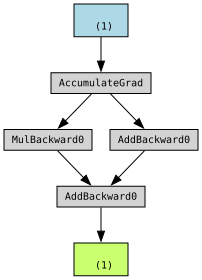

In [10]:
x = torch.tensor([1.0], requires_grad=True)
make_dot(x)
make_dot(x**2+1)
make_dot((x**2+1)**2)
y=2*x
z=3+x
r=y+z
make_dot(r)

In [11]:
x = torch.tensor(2.0, requires_grad=True)
l = 4 * x**3 - 3 * x**2 + 2 * x
l.backward()
print(l, x.grad)

tensor(24., grad_fn=<AddBackward0>) tensor(38.)


In [12]:
x = torch.tensor([-1.0, 2.0, 4.0], requires_grad=True)
l = 3 * x[0] ** 2 - 2 * x[1] ** 2 + 5 * x[2]
l.backward()
print(x.grad)

tensor([-6., -8.,  5.])


In [13]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(-1.0, requires_grad=True)
f = x**2 * y + 3 * x * y**2 + y
f.backward()
print(x.grad, y.grad)

tensor(-1.) tensor(-7.)


In [ ]:
x = torch.tensor(4.0, requires_grad=True)
a = 2 * x + 1
b = a**3
l = torch.sqrt(b)
l.backward()
print(x.grad)

tensor(9.)


In [18]:
pred = torch.tensor([2.0, 4.0, 6.0], requires_grad=True)
target = torch.tensor([1.0, 3.0, 5.0])
l = torch.mean((pred - target) ** 2)
l.backward()
print(pred.grad)

tensor([0.6667, 0.6667, 0.6667])


In [20]:
x = torch.tensor([2.0, 3.0], requires_grad=True)
a = (x**2).sum()
a.backward()
b = (4 * x).sum()
b.backward()
print(x.grad)
x.grad.zero_()
print(x.grad)

tensor([ 8., 10.])
tensor([0., 0.])


In [21]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x**3
gradient = torch.tensor([1.0, 0.5, -1.0])
y.backward(gradient)
print(x.grad)

tensor([  3.,   6., -27.])


In [22]:
x = torch.tensor(2.0, requires_grad=True)
a = 3 * x - 1
a.retain_grad()
b = a**2
b.retain_grad()
l = 2 * b + 5
l.backward()
print(x.grad, a.grad, b.grad)

tensor(60.) tensor(20.) tensor(2.)


In [28]:
x = torch.tensor(3.0, requires_grad=True)
z = torch.tensor(2.0, requires_grad=True)
f = x**2 * z + 3 * z**2 + 4 * x
a = torch.autograd.grad(f, (x, z))
print(f, a, x.grad, z.grad)

tensor(42., grad_fn=<AddBackward0>) (tensor(16.), tensor(21.)) None None


In [30]:
x = torch.tensor(2.0, requires_grad=True)
a = x**2
with torch.no_grad():
    b = 3 * x + 2
c = a + b
c.backward()
print(x.requires_grad, a.requires_grad, b.requires_grad, c.requires_grad)
print(b.grad_fn, x.grad)
u = torch.tensor(3.0, requires_grad=True)
u.requires_grad = False
v = u**2
print(u.requires_grad, v.requires_grad, v.grad_fn)

True True False True
None tensor(4.)
False False None
